# 04 · NAFNet (GoPro): motion-blur removal

**What it is.** NAFNet (*Nonlinear Activation Free Network*, Chen et al., ECCV 2022) trained on the GoPro motion-blur dataset (`NAFNet-GoPro-width64.pth`, 259 MB). Pretrained, MIT licence.

This notebook measures it with a **ground truth**: sharp public photographs are blurred artificially (known motion-blur kernel), restored by NAFNet and by a classical unsharp-mask baseline, and compared with the original sharp photograph (PSNR / SSIM, higher is better).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


## 1 · Synthetic motion blur → restoration

In [2]:
from enhancement.hd_restoration import deblur_with_nafnet

def motion_blur(image, length=15, angle=20):
    kernel = np.zeros((length, length), np.float32); kernel[length // 2, :] = 1
    matrix = cv2.getRotationMatrix2D((length / 2 - 0.5, length / 2 - 0.5), angle, 1)
    kernel = cv2.warpAffine(kernel, matrix, (length, length)); kernel /= kernel.sum()
    return cv2.filter2D(image, -1, kernel)

def unsharp(image):
    return cv2.addWeighted(image, 1.8, cv2.GaussianBlur(image, (0, 0), 3), -0.8, 0)

sharp_ids = sorted(public_stock_ids(), key=lambda pk: -sharpness(photo(pk, 700)))[:6]
rows, shown = [], []
for pk in sharp_ids:
    truth = photo(pk, 700); blurred = motion_blur(truth)
    restored, seconds = timed(lambda: first(deblur_with_nafnet(blurred)))
    base = unsharp(blurred)
    rows.append({"photo": pk, "psnr_blurred": round(psnr(truth, blurred), 2), "psnr_unsharp": round(psnr(truth, base), 2), "psnr_nafnet": round(psnr(truth, restored), 2),
                 "ssim_blurred": round(ssim(truth, blurred), 3), "ssim_unsharp": round(ssim(truth, base), 3), "ssim_nafnet": round(ssim(truth, restored), 3), "seconds": round(seconds, 1)})
    shown.append((truth, blurred, base, restored))
table(rows)

photo  psnr_blurred  psnr_unsharp  psnr_nafnet  ssim_blurred  ssim_unsharp  ssim_nafnet  seconds
-----  ------------  ------------  -----------  ------------  ------------  -----------  -------
74     18.63         18.15         19.63        0.78          0.766         0.868        5.5    
88     26.04         26.18         31.18        0.794         0.796         0.895        2.4    
97     26.75         26.89         31.7         0.836         0.849         0.924        2.3    
75     31.47         31.69         34.83        0.795         0.798         0.855        3.4    
101    27.14         27.36         32.52        0.794         0.798         0.918        2.9    
79     32.35         32.38         35.71        0.866         0.87          0.929        2.3    


mean PSNR  blurred 27.06 | unsharp 27.11 | NAFNet 30.93 dB
mean SSIM  blurred 0.811 | unsharp 0.813 | NAFNet 0.898


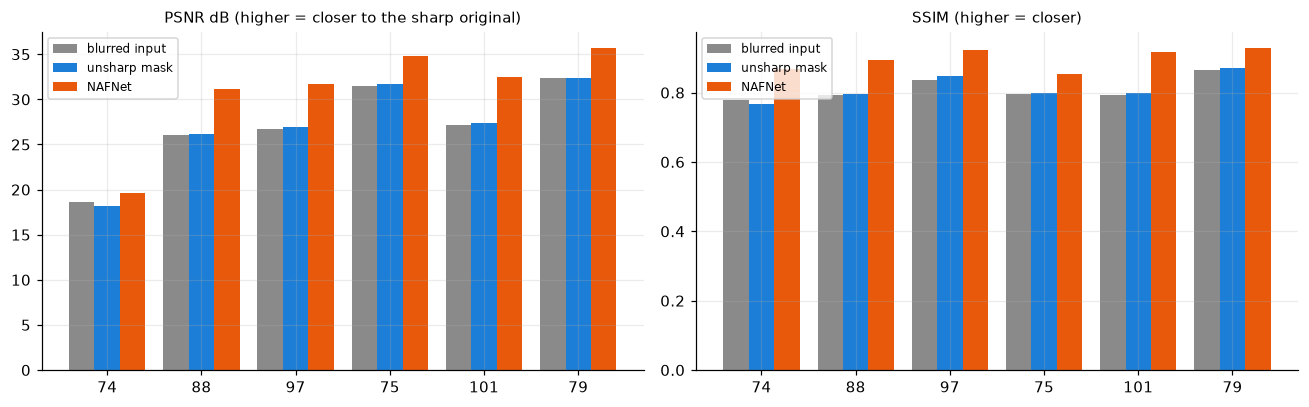

In [3]:
x = np.arange(len(rows)); w = 0.27
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for axis, key, label in ((ax[0], "psnr", "PSNR dB (higher = closer to the sharp original)"), (ax[1], "ssim", "SSIM (higher = closer)")):
    axis.bar(x - w, [r[f"{key}_blurred"] for r in rows], w, label="blurred input", color=COLORS["input"])
    axis.bar(x, [r[f"{key}_unsharp"] for r in rows], w, label="unsharp mask", color=COLORS["baseline"])
    axis.bar(x + w, [r[f"{key}_nafnet"] for r in rows], w, label="NAFNet", color=COLORS["model"])
    axis.set_xticks(x, [r["photo"] for r in rows]); axis.set_title(label, fontsize=10); axis.legend(fontsize=8)
fig.tight_layout(); save(fig, "04_nafnet_gopro_scores.png")
print("mean PSNR  blurred %.2f | unsharp %.2f | NAFNet %.2f dB" % tuple(np.mean([r[k] for r in rows]) for k in ("psnr_blurred", "psnr_unsharp", "psnr_nafnet")))
print("mean SSIM  blurred %.3f | unsharp %.3f | NAFNet %.3f" % tuple(np.mean([r[k] for r in rows]) for k in ("ssim_blurred", "ssim_unsharp", "ssim_nafnet")))

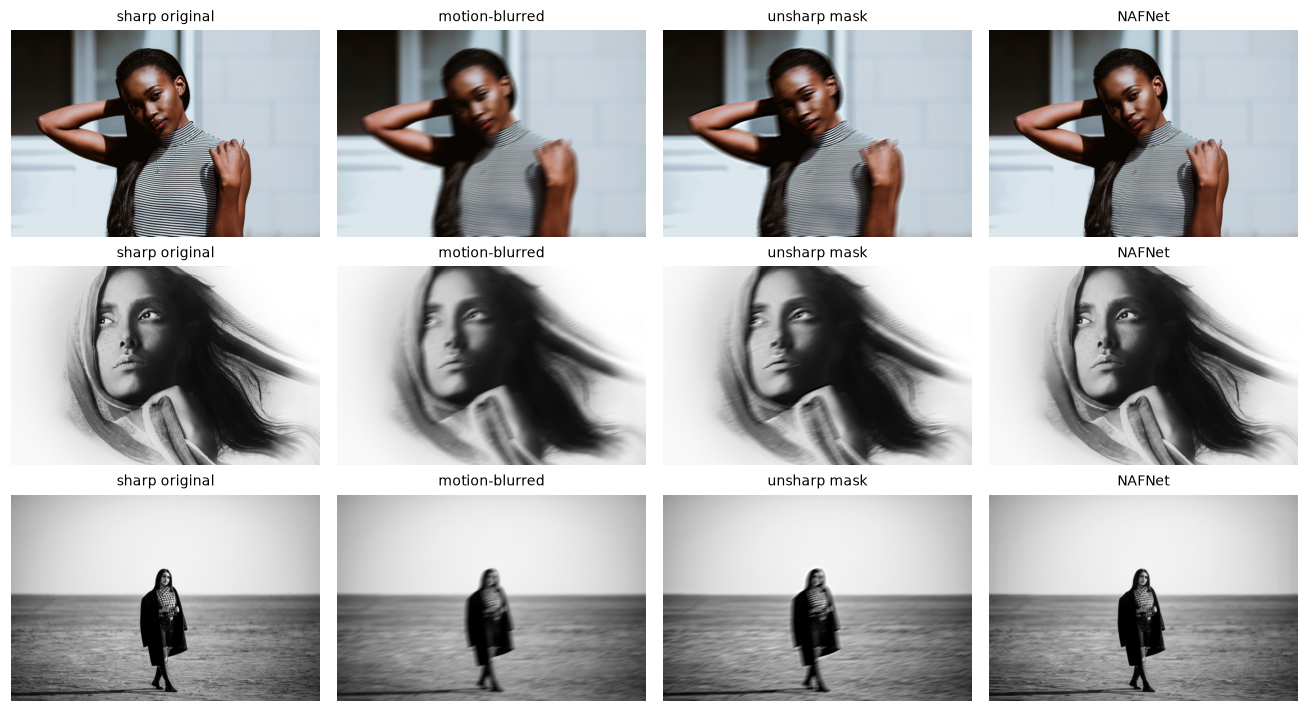

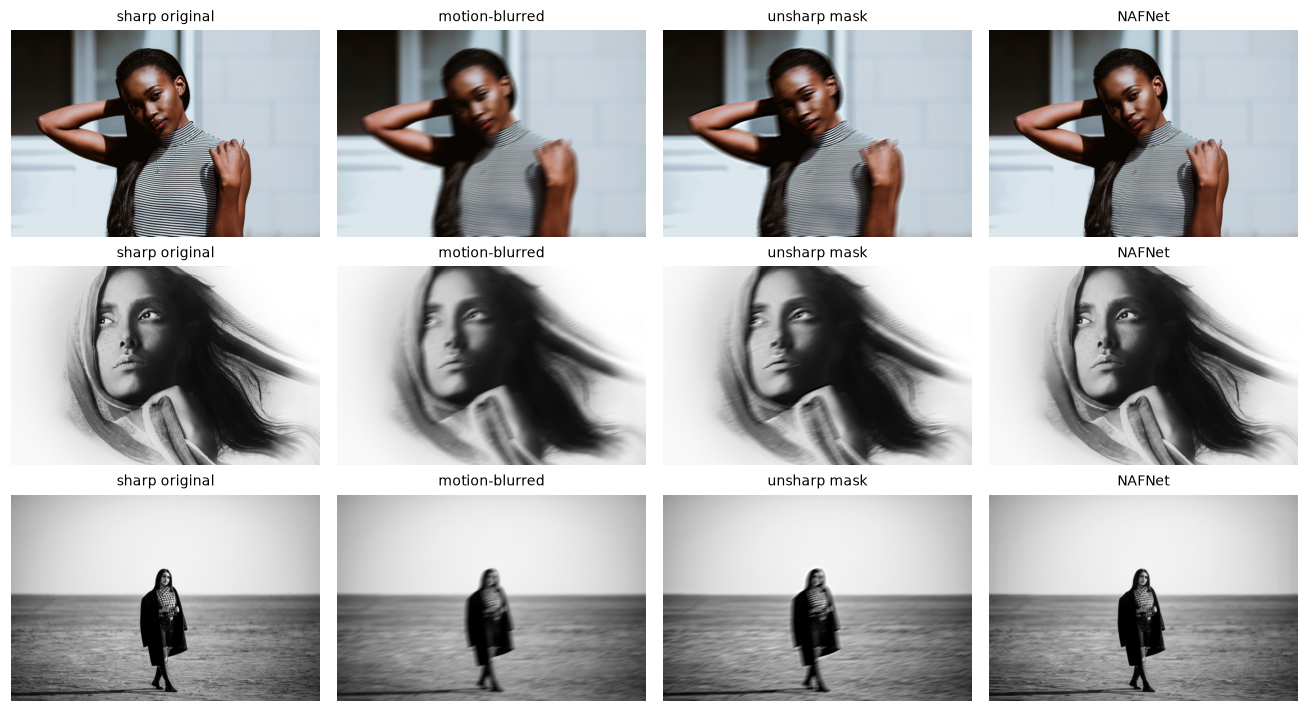

In [4]:
pick = shown[:3]
images = [im for q in pick for im in q]; titles = [t for i in range(len(pick)) for t in ("sharp original", "motion-blurred", "unsharp mask", "NAFNet")]
fig = montage(images, titles, columns=4, width=3.0); fig.set_size_inches(12, 2.2 * len(pick)); save(fig, "04_nafnet_gopro_examples.png")

## 2 · Is it used by the application? (database)

In [5]:
from collections import Counter
from enhancement.models import ImageEnhancementResult
run, accepted = Counter(), Counter()
for result in ImageEnhancementResult.objects.filter(status="completed"):
    for stage in (result.applied_parameters.get("adaptive") or {}).get("stages") or []:
        if stage["operation"] == "motion_deblurring":
            for engine in stage.get("models_run") or []:
                run[engine] += 1; accepted[engine] += stage.get("status") == "accepted"
print("motion_deblurring stage, engines run / accepted:", dict(run), dict(accepted))
save_json("04_nafnet_gopro.json", {"rows": rows, "pipeline_runs": dict(run), "pipeline_accepted": dict(accepted)})

motion_deblurring stage, engines run / accepted: {'nafnet_gopro': 65} {'nafnet_gopro': 23}


## Scorecard (evaluation metrics)

In [6]:
metrics = {"images": len(rows)}
for k, idx in (("blurred", 1), ("unsharp", 2), ("nafnet", 3)):
    metrics[f"psnr_{k}_db"] = float(np.mean([r[f"psnr_{k}"] for r in rows])); metrics[f"ssim_{k}"] = float(np.mean([r[f"ssim_{k}"] for r in rows]))
    metrics[f"mae_{k}"] = float(np.mean([mae(q[0], q[idx]) for q in shown]))
metrics["mean_seconds"] = float(np.mean([r["seconds"] for r in rows]))
metrics["psnr_gain_over_input_db"] = metrics["psnr_nafnet_db"] - metrics["psnr_blurred_db"]
print(scorecard("NAFNet GoPro", "motion deblur", metrics, "synthetic motion blur with ground truth, 6 public photos"))

{'task': 'motion deblur', 'metrics': {'images': 6, 'psnr_blurred_db': 27.0633, 'ssim_blurred': 0.8108, 'mae_blurred': 6.1159, 'psnr_unsharp_db': 27.1083, 'ssim_unsharp': 0.8128, 'mae_unsharp': 6.1309, 'psnr_nafnet_db': 30.9283, 'ssim_nafnet': 0.8982, 'mae_nafnet': 4.0572, 'mean_seconds': 3.1333, 'psnr_gain_over_input_db': 3.865}, 'note': 'synthetic motion blur with ground truth, 6 public photos'}


## 3 · Verdict
NAFNet recovers detail that a classical sharpen cannot (higher PSNR/SSIM against the true sharp image). On real photographs the pipeline still *judges* its output (structure, identity, halo gates) because a deblurring network can invent texture. A heavily blurred photograph is refused up front (`too_blurry_to_enhance`) instead of being "fixed".